In [7]:
import warnings

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import auc, confusion_matrix, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import shuffle as sk_shuffle
from toolbox import (
    Masking,
    augment_patient_and_cat_specific,
    find_all_indices,
    hot_coding,
    visualize_Category_hist,
)
from toolbox.loading import load_data

In [8]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
# set prints off
mask.prints = False

## Contents

- SNR Data augmentation tuning
- Model tuning
    - SVM tuning
    - RF tuning
    - LR tuning



**Data loading**

In [9]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [10]:
# class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
class_task = "MC"

data_augmentation = True


MC

Healthy: 89 entries
Cancer: 91 entries
Severe dysplasia: 24 entries
Benign: 22 entries
Available cases: ['Benign' 'Cancer' 'Healthy' 'Severe dysplasia']
Coding: -> forward
{np.str_('Benign'): [1, 0, 0, 0], np.str_('Cancer'): [0, 1, 0, 0], np.str_('Healthy'): [0, 0, 1, 0], np.str_('Severe dysplasia'): [0, 0, 0, 1]}

Inverse mapping: {(1, 0, 0, 0): 'Benign', (0, 1, 0, 0): 'Cancer', (0, 0, 1, 0): 'Healthy', (0, 0, 0, 1): 'Severe dysplasia'}
(226, 31, 7728) (226, 4) (226,)

		Before augmentation


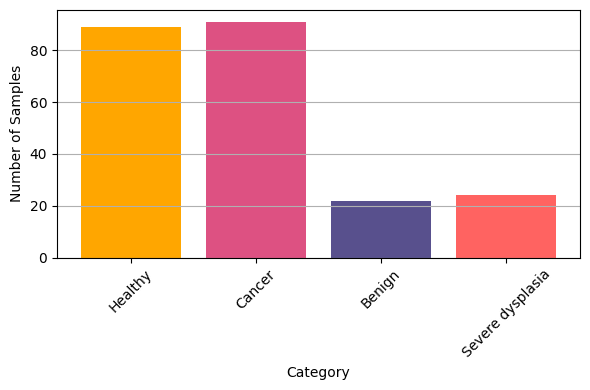

Severe dysplasia to be created: 70

---
Severe dysplasia pat_count_dict={15: 1, 17: 1, 28: 2, 37: 1, 50: 1, 55: 1, 59: 2, 61: 1, 62: 2, 66: 2, 71: 2, 72: 1, 88: 2, 91: 1, 93: 1, 94: 2, 97: 1}
---
Benign to be created: 70

---
Benign pat_count_dict={5: 1, 20: 1, 21: 1, 28: 1, 33: 2, 36: 1, 47: 1, 48: 1, 52: 1, 54: 2, 56: 3, 57: 1, 59: 1, 80: 1, 82: 1, 86: 1, 95: 1, 98: 1}
---
Benign: 72 entries
Cancer: 91 entries
Healthy: 89 entries
Severe dysplasia: 71 entries

		After augmentation


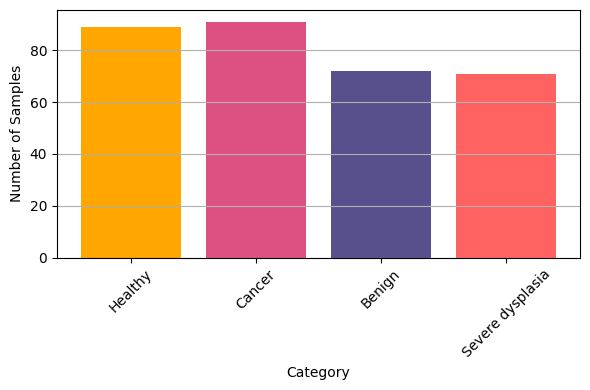

In [11]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    # for SVD kernel boundary
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        1: "#003F5C",  # healthy
        0: "#FFA600",  # cancer
    }
    cp_l = {
        1: "healthy",  # healthy
        0: "cancer",  # cancer
    }
    visualize_Category_hist(labels)

elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        1: "#DD5182",  # non-cancer
        0: "#FFA600",  # cancer
    }
    cp_l = {
        1: "healthy",  # non-cancer
        0: "cancer",  # cancer
    }
    visualize_Category_hist(labels)

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        0: "#58508D",  # Benign
        1: "#FFA600",  # Cancer
        2: "#003F5C",  # Healthy
        3: "#FF6361",  # Severe dysplasia
    }
    cp_l = {
        0: "Benign",
        1: "Cancer",
        2: "Healthy",
        3: "Severe dysplasia",
    }
    aug_dict = {
        "Severe dysplasia": 70,
        "Benign": 70,
    }
    
Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

if class_task == "MC" and data_augmentation:
    print("\n\t\tBefore augmentation")    
    visualize_Category_hist(labels)
    X, Y_labels, labels, Case = augment_patient_and_cat_specific(
        X, Y_labels, labels, Case, aug_dict
    )
    print("\n\t\tAfter augmentation")
    visualize_Category_hist(labels)

# Model tuning

**Tuning using `GridSearch()` with `GroupKFold()` train/test data split**

- SVM tuning
- RF tuning
- LR tuning

In [12]:
n_folds = 5  # number of iterations inside each LPOCV
output_prints = False

# load frequency selection
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]

Freq_sel = {
    "Top 2": top_freqs_baseline[:2],
    "Top 3": top_freqs_baseline[:3],
    "Top 5": top_freqs_baseline[:5],
    "Top 12": top_freqs_baseline[:12],
    # "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

# load masking selection
tmp = np.load(f"results/Top_IIVV_masks_{class_task}.npz", allow_pickle=True)
Mask_ranks = tmp["Mask_ranks"][:4]

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}
Mask_sel = {k: v for k, v in Mask_sel.items() if k in Mask_ranks}

## SVM tuning

In [13]:
stats_df = []
use_model = "SVM"

param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": np.logspace(-3, 3, 7, dtype=float),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
for Fsel in Freq_sel.keys():
    for Msel in Mask_sel.keys():
        for random_state in range(10):

            cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)
            """
            for fold, (train_idx, test_idx) in enumerate(cv.split(X_tmp, Y_labels, groups=Case), 1):
                print(f"Fold {fold}")
                print("  Train groups:", Case[train_idx])
                print("  Test groups :", Case[test_idx])
                print("  Train idx   :", train_idx)
                print("  Test idx    :", test_idx)
                print()
            """
            m = SVC(probability=True, random_state=random_state)

            grid_search = GridSearchCV(
                estimator=m,
                param_grid=param_grid,
                cv=cv,
                scoring="roc_auc_ovr",
                n_jobs=80,
            )

            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            # select freq and IIVV and shape data
            X_tmp = X[:, Freq_sel[Fsel], :]
            X_tmp = X_tmp[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

            grid_search.fit(X_tmp, Y_labels, groups=Case)

            best_params = grid_search.best_params_
            best_score = grid_search.best_score_

            if output_prints:
                print(f"\nRandom_state{random_state}")
                print("Best parameters:", best_params)
                print("Best ROC AUC:", best_score)

            df_row = {
                "Architecture": use_model,
                "Fsel": Fsel,
                "Msel": Msel,
                "n_params": X_tmp.shape[1],
                "Random_state": random_state,
                "val AUC": best_score,
            }
            df_row.update(best_params)
            stats_df.append(df_row)

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_SVM_{class_task}.csv", index=False)

In [14]:
param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": np.logspace(-3, 3, 7, dtype=float),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_SVM_{class_task}.csv")

In [15]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

  hpt_combinations   val AUC
0        poly_10.0  0.946766
1         rbf_10.0  0.938644
2        rbf_100.0  0.936027
3       rbf_1000.0  0.931122

Column: hpt_combinations
hpt_combinations
rbf_100.0     74
rbf_10.0      59
rbf_1000.0    22
poly_10.0      5
Name: count, dtype: int64


[Plot-svm-kernels](https://scikit-learn.org/stable/auto_examples/svm/plot_svm_kernels.html#rbf-kernel)

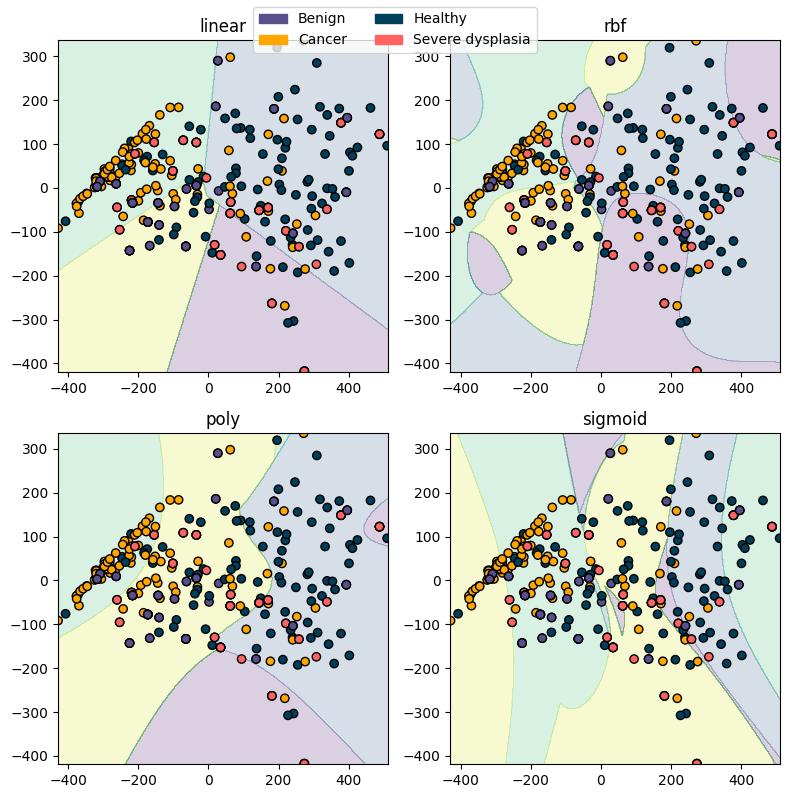

In [16]:
C_val = 10

X_flat = X.reshape(X.shape[0], -1)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_flat)

kernels = ["linear", "rbf", "poly", "sigmoid"]
colors = [cp[label] for label in Y_labels]
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=10)
    clf.fit(X_2d, Y_labels)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, -1 * Z, alpha=0.2)
    scatter = axes[i].scatter(X_2d[:, 0], X_2d[:, 1], c=colors, edgecolor="k")
    axes[i].set_title(f"{kernel}")
    legend_handles = [mpatches.Patch(color=cp[k], label=cp_l[k]) for k in cp.keys()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    f"results/SVM_kernels_{class_task}_{C_val}.pdf",
    bbox_inches="tight",
)
plt.show()

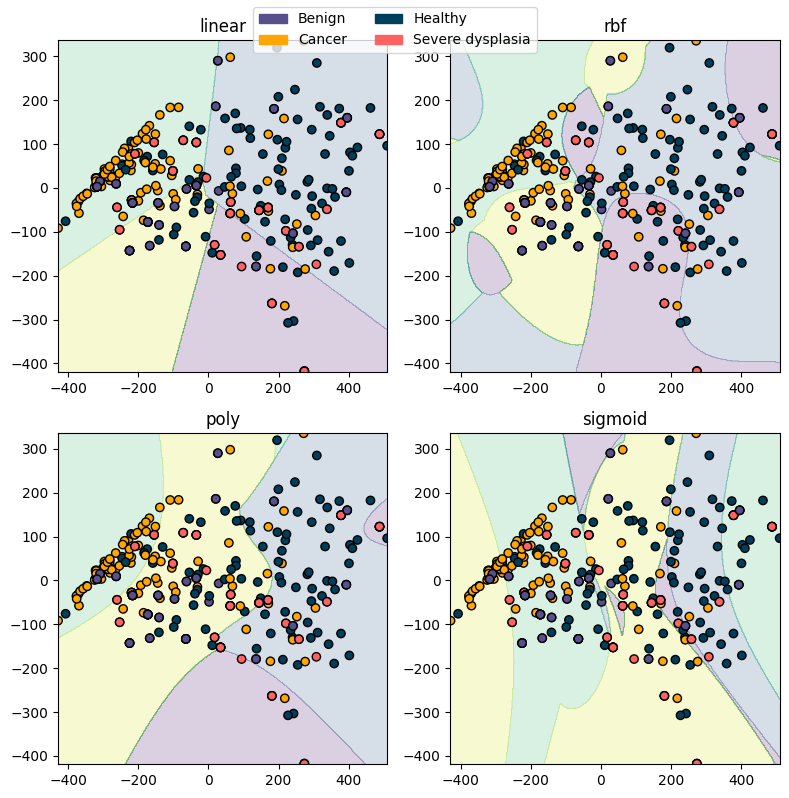

In [17]:
C_val = 1000

X_flat = X.reshape(X.shape[0], -1)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_flat)

kernels = ["linear", "rbf", "poly", "sigmoid"]
colors = [cp[label] for label in Y_labels]
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=10)
    clf.fit(X_2d, Y_labels)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, -1 * Z, alpha=0.2)
    scatter = axes[i].scatter(X_2d[:, 0], X_2d[:, 1], c=colors, edgecolor="k")
    axes[i].set_title(f"{kernel}")
    legend_handles = [mpatches.Patch(color=cp[k], label=cp_l[k]) for k in cp.keys()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    f"results/SVM_kernels_{class_task}_{C_val}.pdf",
    bbox_inches="tight",
)
plt.show()

## RF tuning

In [ ]:
stats_df = []
use_model = "RF"

param_grid = {
    "n_estimators": [100, 300, 500, 800],
    "max_depth": [510, 20, None],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}
for Fsel in Freq_sel.keys():
    for Msel in Mask_sel.keys():
        for random_state in range(10):
            cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)

            m = RandomForestClassifier(random_state=random_state)

            grid_search = GridSearchCV(
                estimator=m,
                param_grid=param_grid,
                cv=cv,
                scoring="roc_auc_ovr",
                n_jobs=80,
            )
            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            # select freq and IIVV and shape data
            X_tmp = X[:, Freq_sel[Fsel], :]
            X_tmp = X_tmp[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

            grid_search.fit(X_tmp, Y_labels, groups=Case)

            best_params = grid_search.best_params_
            best_score = grid_search.best_score_

            if output_prints:
                print(f"\nRandom_state{random_state}")
                print("Best parameters:", best_params)
                print("Best ROC AUC:", best_score)

            df_row = {
                "Architecture": use_model,
                "Fsel": Fsel,
                "Msel": Msel,
                "n_params": X_tmp.shape[1],
                "Random_state": random_state,
                "val AUC": best_score,
            }
            df_row.update(best_params)
            stats_df.append(df_row)
df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_RF_{class_task}.csv", index=False)

In [ ]:
param_grid = {
    "n_estimators": [100, 300, 500, 800],
    "max_depth": [510, 20, None],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_RF_{class_task}.csv")

In [ ]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

### LR tuning

In [ ]:
stats_df = []
use_model = "LR"

param_grid = {
    # "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.01, 0.1, 1, 10, 100],
    "max_iter": [100, 1000, 10_000],
    # "solver": ["saga"],
}

for Fsel in Freq_sel.keys():
    for Msel in Mask_sel.keys():
        for random_state in range(10):
            cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)

            m = LogisticRegression(random_state=random_state)

            grid_search = GridSearchCV(
                estimator=m,
                param_grid=param_grid,
                cv=cv,
                scoring="roc_auc_ovr",
                n_jobs=80,
            )
            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            # select freq and IIVV and shape data
            X_tmp = X[:, Freq_sel[Fsel], :]
            X_tmp = X_tmp[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

            grid_search.fit(X_tmp, Y_labels, groups=Case)

            best_params = grid_search.best_params_
            best_score = grid_search.best_score_

            if output_prints:
                print(f"\nRandom_state{random_state}")
                print("Best parameters:", best_params)
                print("Best ROC AUC:", best_score)

            df_row = {
                "Architecture": use_model,
                "Fsel": Fsel,
                "Msel": Msel,
                "n_params": X_tmp.shape[1],
                "Random_state": random_state,
                "val AUC": best_score,
            }
            df_row.update(best_params)
            stats_df.append(df_row)

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_LR_{class_task}.csv", index=False)

In [ ]:
param_grid = {
    # "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.01, 0.1, 1, 10, 100],
    "max_iter": [100, 1000, 10_000],
    # "solver": ["saga"],
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_LR_{class_task}.csv")

In [ ]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

## SNR Data augmentation tuning

### Train and test split

In [18]:
random_state = 0
n_folds = 5


def generate_folds(Case, n_folds, random_state):
    unique_patients = np.unique(Case)
    np.random.seed(random_state)

    # Check if Y is in one-hot encoding
    if len(Y.shape) == 1 or Y.shape[1] == 1:
        raise ValueError("Labels (Y) must be in one-hot encoding format")
    # Custom splitting to ensure 70/30 ratio
    patient_indices = np.arange(len(unique_patients))
    np.random.shuffle(patient_indices)

    # Split these indices into n_folds
    fold_size = len(patient_indices) // n_folds
    folds = []

    for i in range(n_folds):
        if i == n_folds - 1:
            # Last fold gets all remaining patients
            test_indices = patient_indices[i * fold_size :]
        else:
            test_indices = patient_indices[i * fold_size : (i + 1) * fold_size]
        # Training indices are all other indices
        train_indices = np.setdiff1d(patient_indices, test_indices)
        folds.append((train_indices, test_indices))

    return folds


folds = generate_folds(Case, n_folds, random_state)

**Data augmentation for training data**

In [19]:
def add_noise_2d(signal, snr_db):
    signal_power = np.nanmean(signal**2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear
    noise = np.sqrt(noise_power) * np.random.normal(size=signal.shape)
    return signal + noise


def select_cat_data(X, Y, select: int):
    """
    Get all indices of a single category
    """
    matches = np.all(Y == select, axis=1)
    idxs = np.where(matches)[0]

    return X[idxs, ...], idxs


def data_augmentation(
    X, Y, tar_num, snr_db, shuffle_data=True, random_state=42, prints=True
):
    if len(Y.shape) == 2:
        cats = np.unique(Y, axis=0)
    else:
        cats = np.unique(Y)
    X_aug = list()
    Y_aug = list()

    for selected_cat in cats:
        X_select, idxs = select_cat_data(X, Y, selected_cat)
        aug_num = tar_num - len(idxs)
        aug_idxs = np.random.randint(0, len(idxs), size=aug_num)

        if prints:
            print(
                f"There are {len(idxs)} available samples, {aug_num} will be created."
            )

        for Xs in X_select:
            X_aug.append(Xs)
            Y_aug.append(selected_cat)

        # augmentation:
        for aug_idx in aug_idxs:
            Xs_noisy = add_noise_2d(X_select[aug_idx], snr_db)
            X_aug.append(Xs_noisy)
            Y_aug.append(selected_cat)
    X_aug = np.array(X_aug)
    Y_aug = np.array(Y_aug)
    if shuffle_data:
        X_aug, Y_aug = sk_shuffle(X_aug, Y_aug, random_state=random_state)

    return X_aug, Y_aug

**The data augmentation is implemented here and will be called during the 5-fold cross validation!**

In [20]:
from toolbox.model import Model

In [10]:
# load frequency selection
output_prints = False

# load frequency selection
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]

Freq_sel = {
    "Top 2": top_freqs_baseline[:2],
    "Top 3": top_freqs_baseline[:3],
    "Top 5": top_freqs_baseline[:5],
    "Top 12": top_freqs_baseline[:12],
    # "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

# load masking selection
tmp = np.load(f"results/Top_IIVV_masks_{class_task}.npz", allow_pickle=True)
Mask_ranks = tmp["Mask_ranks"][:4]

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}
Mask_sel = {k: v for k, v in Mask_sel.items() if k in Mask_ranks}


MC



In [ ]:
stats_df = []
Fsel = "Top 3"
Msel = "Skip1 medium"

mask.IIVV_mask(Mask_sel[Msel])

use_models = [
    "SVM",
    # "RF",
    # "LR",
]
SNRs = [10, 20, 30, 40, 50]

for snr_db in SNRs:
    print("SNR=", snr_db)
    for random_state in range(10):
        print("\trandom_state", random_state)
        folds = generate_folds(Case, n_folds, random_state)
        for fold_idx, (train_patients_idx, test_patients_idx) in enumerate(folds):
            fold = fold_idx + 1
            # Get patient IDs for training and testing
            unique_patients = np.unique(Case)
            train_patients = unique_patients[train_patients_idx]
            test_patients = unique_patients[test_patients_idx]
            # Create masks for training and testing samples
            train_mask = np.isin(Case, train_patients)
            test_mask = np.isin(Case, test_patients)
            # Get training and testing data
            X_train, Y_train = data_augmentation(
                X[train_mask],
                Y[train_mask],
                target_num_augmentation,
                snr_db,
                shuffle_data=True,
                random_state=random_state,
                prints=False,
            )
            # unaugmented test data:
            X_test = X[test_mask]
            Y_test = Y[test_mask]
            # here the frequency and IIVV selection is done
            X_train = X_train[:, Freq_sel[Fsel], :]
            X_test = X_test[:, Freq_sel[Fsel], :]
            # IIVV selection
            X_train = X_train[:, :, mask.mask]
            X_test = X_test[:, :, mask.mask]
            # Reshape
            X_train = X_train.reshape(X_train.shape[0], -1)
            X_test = X_test.reshape(X_test.shape[0], -1)
            # ------ Models ------
            for use_model in use_models:
                try:
                    pf = Model(
                        use_model,
                        X_train,
                        Y_train,
                        X_test,
                        Y_test,
                        random_state,
                        inverse_mapping,
                        fold,
                        Msel,
                        Fsel,
                        class_task,
                    )
                    stats_df.append({**pf, "SNR": snr_db})
                except:
                    print("Failed")
            # -----------------

df = pd.DataFrame(stats_df)
df.to_csv(f"results/SNR_tuning_{class_task}_{Fsel}_{Msel}.csv", index=False)

In [ ]:
df = pd.read_csv(f"results/SNR_tuning_{class_task}_{Fsel}_{Msel}.csv")

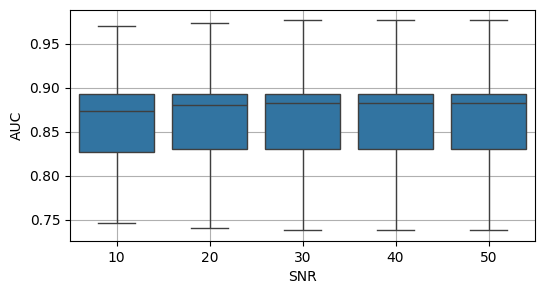

In [12]:
plt.figure(figsize=(6, 3))
sns.boxplot(data=df, x="SNR", y="ROC AUC")
plt.ylabel("AUC")
plt.xlabel("SNR")
plt.grid()
plt.show()

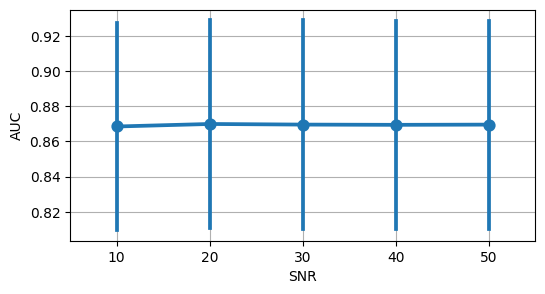

In [13]:
plt.figure(figsize=(6, 3))
sns.pointplot(data=df, x="SNR", y="ROC AUC", ci="sd", markers="o")
plt.grid()
plt.ylabel("AUC")
plt.xlabel("SNR")
plt.show()

In [14]:
# based on the `snr_db = 30  # dB` tuning results:
snr_db = df.groupby("SNR")["ROC AUC"].mean().idxmax()
print("Best SNR:", snr_db)

Best SNR: 20


___